<a href="https://colab.research.google.com/github/mrayhanz/244107020027-Machine-Learning/blob/main/Minggu%206/MRayhanZamzami_JS06_ANN_P3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IDENTITAS DIRI

Nama : Muhammad Rayhan Zamzami

NIM : 244107020027

Kelas : TI-3G

Absen : 19

# PRAKTIKUM 3 - Hierarchical Navigable Small World (HNSW)


In [1]:
# Instalasi hnswlib jika dijalankan di Google Colab
!pip install hnswlib

### 1. Implementasi HNSW vs Exact Nearest Neighbors (1.000 Data 2D)

=== Exact NN ===
Indices: [[137 170 750 316 991]]
Distances: [[0.01144331 0.0278216  0.02824018 0.03417073 0.04514859]]
Waktu: 2.0630531311035156 detik

=== HNSW ===
Indices: [[137 170 750 316 991]]
Distances: [[0.00013095 0.00077404 0.00079751 0.00116764 0.0020384 ]]
Waktu: 0.02564382553100586 detik


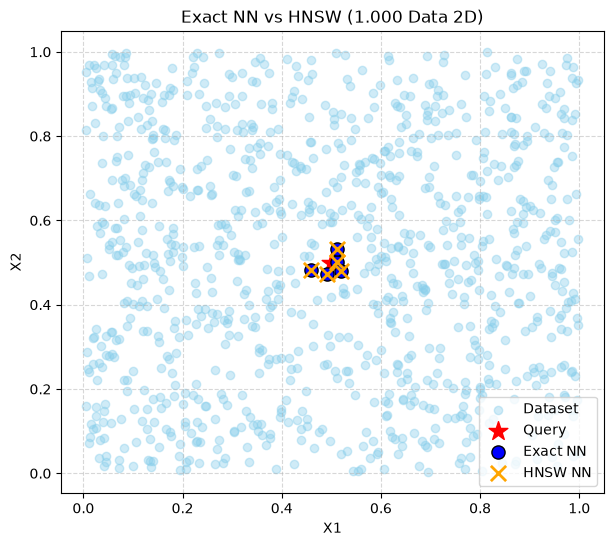

In [2]:
import hnswlib
import numpy as np
import time
from sklearn.neighbors import NearestNeighbors

# ===========================
# 1. Buat data 2D acak
# ===========================
np.random.seed(42)
num_elements = 1000
dim = 2
data = np.random.random((num_elements, dim)).astype(np.float32)

# Query point
query = np.array([[0.5, 0.5]], dtype=np.float32)
k = 5  # cari 5 tetangga terdekat

# ===========================
# 2. Exact NN (Brute Force)
# ===========================
nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric='euclidean')
nn.fit(data)

start = time.time()
distances, indices = nn.kneighbors(query)
end = time.time()

print("=== Exact NN ===")
print("Indices:", indices)
print("Distances:", distances)
print("Waktu:", end - start, "detik")

# ===========================
# 3. HNSW
# ===========================
# Inisialisasi index HNSW
p = hnswlib.Index(space='l2', dim=dim)

# Ukuran maksimum elemen yang bisa ditampung
p.init_index(max_elements=num_elements, ef_construction=100, M=16)

# Tambahkan data
p.add_items(data)

# Set parameter pencarian
p.set_ef(50)   # tradeoff speed vs accuracy

start = time.time()
labels, distances = p.knn_query(query, k=k)
end = time.time()

print("\n=== HNSW ===")
print("Indices:", labels)
print("Distances:", distances)
print("Waktu:", end - start, "detik")

# ===========================
# 4. Visualisasi
# ===========================
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))
plt.scatter(data[:, 0], data[:, 1], alpha=0.4, c='skyblue', label='Dataset')
plt.scatter(query[:, 0], query[:, 1], c='red', marker='*', s=200, label='Query')
plt.scatter(data[indices[0], 0], data[indices[0], 1], c='blue', s=90, edgecolor='k', label='Exact NN')
plt.scatter(data[labels[0], 0], data[labels[0], 1], c='orange', marker='x', s=120, linewidth=2, label='HNSW NN')
plt.title('Exact NN vs HNSW (1.000 Data 2D)')
plt.xlabel('X1')
plt.ylabel('X2')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### 2. Eksperimen Variasi Metrik, Jumlah Data, dan Dimensi


In [3]:
import pandas as pd

def benchmark_hnsw(n_samples, dim, space='l2', ef=50, M=16):
    np.random.seed(42)
    X_data = np.random.random((n_samples, dim)).astype(np.float32)
    q_data = np.random.random((1, dim)).astype(np.float32)
    k = 5

    # 1. Exact ground truth
    metric_map = {'l2': 'euclidean', 'cosine': 'cosine', 'ip': 'cosine'}
    t0 = time.time()
    nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric=metric_map[space])
    nn.fit(X_data)
    gt_dist, gt_idx = nn.kneighbors(q_data)
    exact_time = time.time() - t0

    # 2. HNSW
    p = hnswlib.Index(space=space, dim=dim)
    t0 = time.time()
    p.init_index(max_elements=n_samples, ef_construction=200, M=M)
    p.add_items(X_data)
    build_time = time.time() - t0
    p.set_ef(ef)

    t0 = time.time()
    labels, distances = p.knn_query(q_data, k=k)
    query_time = time.time() - t0

    recall = len(set(gt_idx[0]) & set(labels[0])) / k
    return {
        "Jumlah Data": f"{n_samples:,}",
        "Dimensi": f"{dim}D",
        "Metric": space,
        "Exact Time (s)": f"{exact_time:.4f}",
        "HNSW Build (s)": f"{build_time:.4f}",
        "HNSW Query (ms)": f"{query_time*1000:.4f}",
        "Recall@5": f"{recall:.2f}"
    }

configs = [
    (1000, 2, 'l2'), (1000, 2, 'cosine'), (1000, 2, 'ip'),
    (1000, 5, 'l2'), (1000, 5, 'cosine'), (1000, 5, 'ip'),
    (100000, 2, 'l2'), (100000, 2, 'cosine'), (100000, 2, 'ip'),
    (100000, 5, 'l2'), (100000, 5, 'cosine'), (100000, 5, 'ip'),
    (1000000, 2, 'l2'), (1000000, 5, 'l2'),
]

results = [benchmark_hnsw(n, d, s) for n, d, s in configs]
df_hnsw = pd.DataFrame(results)
display(df_hnsw)

,Jumlah Data,Dimensi,Metric,Exact Time (s),HNSW Build (s),HNSW Query (ms),Recall@5
0,"1,000",2D,l2,0.0062,0.0018,22.0387,1.00
1,"1,000",2D,cosine,0.0116,0.0006,34.6358,1.00
2,"1,000",2D,ip,0.0029,0.0007,32.9466,1.00
3,"1,000",5D,l2,0.0073,0.0020,20.6800,1.00
4,"1,000",5D,cosine,0.0033,0.0005,31.5461,1.00
5,"1,000",5D,ip,0.0029,0.0006,37.4129,1.00
6,"100,000",2D,l2,0.0029,0.0987,21.1124,1.00
7,"100,000",2D,cosine,0.0092,0.0007,47.2832,1.00
8,"100,000",2D,ip,0.0071,0.0008,36.8934,1.00
9,"100,000",5D,l2,0.0054,0.1830,19.0134,1.00


### 3. Pengaruh Parameter `ef` terhadap Recall dan Waktu Query

,ef,Recall@10,Query Time (ms/query)
0,10,1.0,0.1157
1,20,1.0,0.1132
2,50,1.0,0.1120
3,100,1.0,0.1120
4,200,1.0,0.1112
5,400,1.0,0.1091


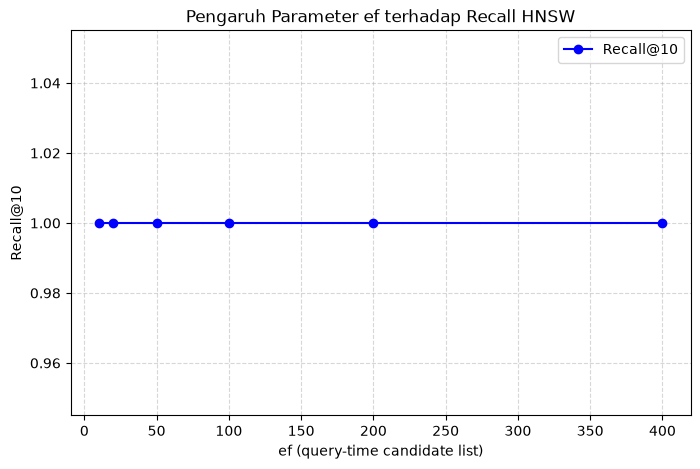

In [4]:
np.random.seed(42)
n, d, k = 50_000, 16, 10
X_data = np.random.random((n, d)).astype(np.float32)
X_query = np.random.random((200, d)).astype(np.float32)

# Ground truth exact
nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric='euclidean').fit(X_data)
_, gt = nn.kneighbors(X_query)

# Build sekali, ubah-ubah ef saat query
p = hnswlib.Index(space='l2', dim=d)
p.init_index(max_elements=n, ef_construction=200, M=16)
p.add_items(X_data)

ef_values = [10, 20, 50, 100, 200, 400]
tabel_ef = []

for ef in ef_values:
    p.set_ef(ef)
    t0 = time.time()
    labels, _ = p.knn_query(X_query, k=k)
    elapsed = (time.time() - t0) * 1000 / len(X_query)
    correct = sum(len(set(labels[i][:k]) & set(gt[i][:k])) for i in range(len(labels)))
    recall = correct / (len(labels) * k)
    tabel_ef.append({"ef": ef, "Recall@10": round(recall, 4), "Query Time (ms/query)": round(elapsed, 4)})

df_ef = pd.DataFrame(tabel_ef)
display(df_ef)

plt.figure(figsize=(8, 5))
plt.plot(df_ef["ef"], df_ef["Recall@10"], marker='o', color='blue', label='Recall@10')
plt.xlabel("ef (query-time candidate list)")
plt.ylabel("Recall@10")
plt.title("Pengaruh Parameter ef terhadap Recall HNSW")
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()